# 08 · Hypothesis Test: Completion Rate

**Author:** Pariya  
**Question:** Is the difference in completion rate between Test and Control statistically significant?

## Import libraries

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

## Load the cleaned data
Reads the 3 cleaned CSV files from `01_data_cleaning.ipynb` (experiment clients only), renames `Variation` to `variation`, and builds `df_clients` (demographics + test group) and `df_web_exp` (web events + test group).

In [2]:
clients_demo = pd.read_csv('cleaned_clients_demographics.csv')
clients_var = pd.read_csv('cleaned_clients_variation.csv')
web_events = pd.read_csv('cleaned_web_events.csv', parse_dates=['date_time'])

clients_var = clients_var.rename(columns={'Variation': 'variation'})

df_clients = clients_var.merge(clients_demo, on='client_id', how='inner')
df_web_exp = web_events.merge(clients_var, on='client_id', how='inner')

## Completion rate per group
*(Same cells as in `05_kpi_completion_rate.ipynb`, needed here for the test.)*

In [3]:
df_confirm = df_web_exp[df_web_exp['process_step']== 'confirm']
df_confirm

,client_id,visitor_id,visit_id,process_step,date_time,variation
8,8320017,39393514_33118319366,960651974_70596002104_312201,confirm,2017-04-05 13:10:05,Test
13,4033851,762728880_76361333336,949661017_22392791362_127391,confirm,2017-04-05 12:29:03,Control
14,4033851,762728880_76361333336,949661017_22392791362_127391,confirm,2017-04-05 12:29:01,Control
15,4033851,762728880_76361333336,949661017_22392791362_127391,confirm,2017-04-05 12:28:52,Control
24,1982004,618934751_10082078917,132494692_73738638511_70823,confirm,2017-04-17 12:02:42,Test
...,...,...,...,...,...,...
317104,6230585,100189756_32488226026,671811152_97876326241_999687,confirm,2017-05-08 09:29:38,Test
317109,4977550,795300798_27713164444,423005536_66563748376_701196,confirm,2017-05-25 15:19:39,Control
317115,6426623,27047012_3402532492,685634090_42070675506_389171,confirm,2017-05-19 05:40:14,Control
317120,433098,5505424_50616523266,773565250_67577573147_389841,confirm,2017-05-13 15:33:04,Control


In [4]:
total_clients = df_web_exp.groupby('variation')['client_id'].nunique()
total_clients

variation
Control    23527
Test       26961
Name: client_id, dtype: int64

In [5]:
confirm_clients = df_confirm.groupby('variation')['client_id'].nunique()
confirm_clients

variation
Control    15429
Test       18682
Name: client_id, dtype: int64

In [6]:
pd.set_option('display.float_format', '{:,.3f}'.format)
completion_rate = confirm_clients /total_clients
completion_rate

variation
Control   0.656
Test      0.693
Name: client_id, dtype: float64

## Hypotheses

- H₀ (null hypothesis): The completion rate is the same for the Control and Test groups. (The new design has no effect on completion.)
- H₁ (alternative hypothesis): The completion rate is different between the Control and Test groups. (The new design has an effect on completion.)

## Contingency table

In [7]:
not_completed= total_clients-confirm_clients
not_completed

variation
Control    8098
Test       8279
Name: client_id, dtype: int64

In [8]:
contingency_table = pd.DataFrame({'completed': confirm_clients, 'not_completed': not_completed})
contingency_table

,completed,not_completed
variation,,
Control,15429,8098
Test,18682,8279


## Chi-square test

In [9]:
from scipy.stats import chi2_contingency

chi2_statistic,chi2_p_value,dof,expected = chi2_contingency(contingency_table)

print(f"p-value: {chi2_p_value:.2e}")

p-value: 6.69e-19


A chi-square test shows that the difference in completion rate between Test (69.3%) and Control (65.6%) is statistically significant (p < 0.001). We reject the null hypothesis: the new design has an effect on completion rate.

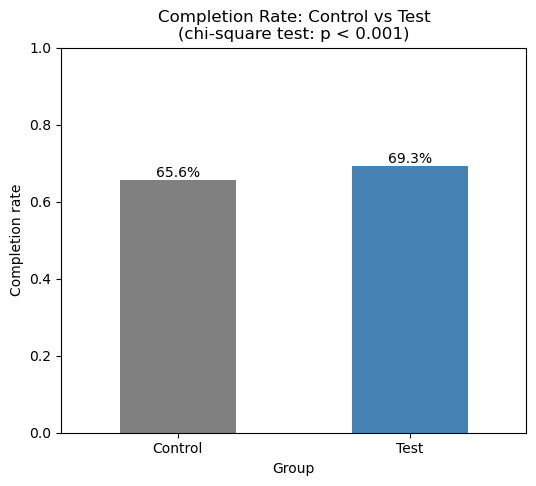

In [10]:
ax = completion_rate.plot(kind='bar', color=['gray', 'steelblue'], figsize=(6, 5))

ax.bar_label(ax.containers[0], labels=[f'{v:.1%}' for v in completion_rate])

plt.title('Completion Rate: Control vs Test\n(chi-square test: p < 0.001)')
plt.xlabel('Group')
plt.ylabel('Completion rate')
plt.ylim(0, 1)
plt.xticks(rotation=0)
plt.show()